<center><h1>Groome_Henry_HW5</h1></center>
<br>
<br>

Name: Henry Groome
<br>
Github Username: hgroome46
<br>
USC ID: 4479346040

## 1. Decision Trees as Interpretable Models

Import packages

In [27]:
import numpy as np         
import pandas as pd

import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

from sklearn.impute import SimpleImputer               
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV 
from sklearn.preprocessing import StandardScaler      
from sklearn.decomposition import PCA                  
from sklearn.pipeline import make_pipeline        
from sklearn.model_selection import cross_val_score, GridSearchCV, KFold
from sklearn.metrics import mean_squared_error 
from sklearn.pipeline import Pipeline

%pip install xgboost
import xgboost as xgb 



Note: you may need to restart the kernel to use updated packages.


### (a) Obtain Data

Get the Accute Inamations Data Set

In [9]:
data_dir = 'Homework 5 Data/'

columns = ['Temperature of patient',
'Occurrence of nausea', 
'Lumbar pain',
'Urine pushing',
'Micturition pains',
'Burning of urethra',
'Inflammation of urinary bladder',
'Nephritis of renal pelvis origin']


diagnosis = pd.read_csv(data_dir + 'diagnosis.csv', encoding='utf-16', sep='\t', decimal=',', header=None, names=columns,)

diagnosis = diagnosis.replace({'yes': 1, 'no': 0})

decision_cols = ['Inflammation of urinary bladder', 'Nephritis of renal pelvis origin']

X = diagnosis.drop(columns=decision_cols)
Y = diagnosis[decision_cols]
diagnosis.head()



,Temperature of patient,Occurrence of nausea,Lumbar pain,Urine pushing,Micturition pains,Burning of urethra,Inflammation of urinary bladder,Nephritis of renal pelvis origin
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

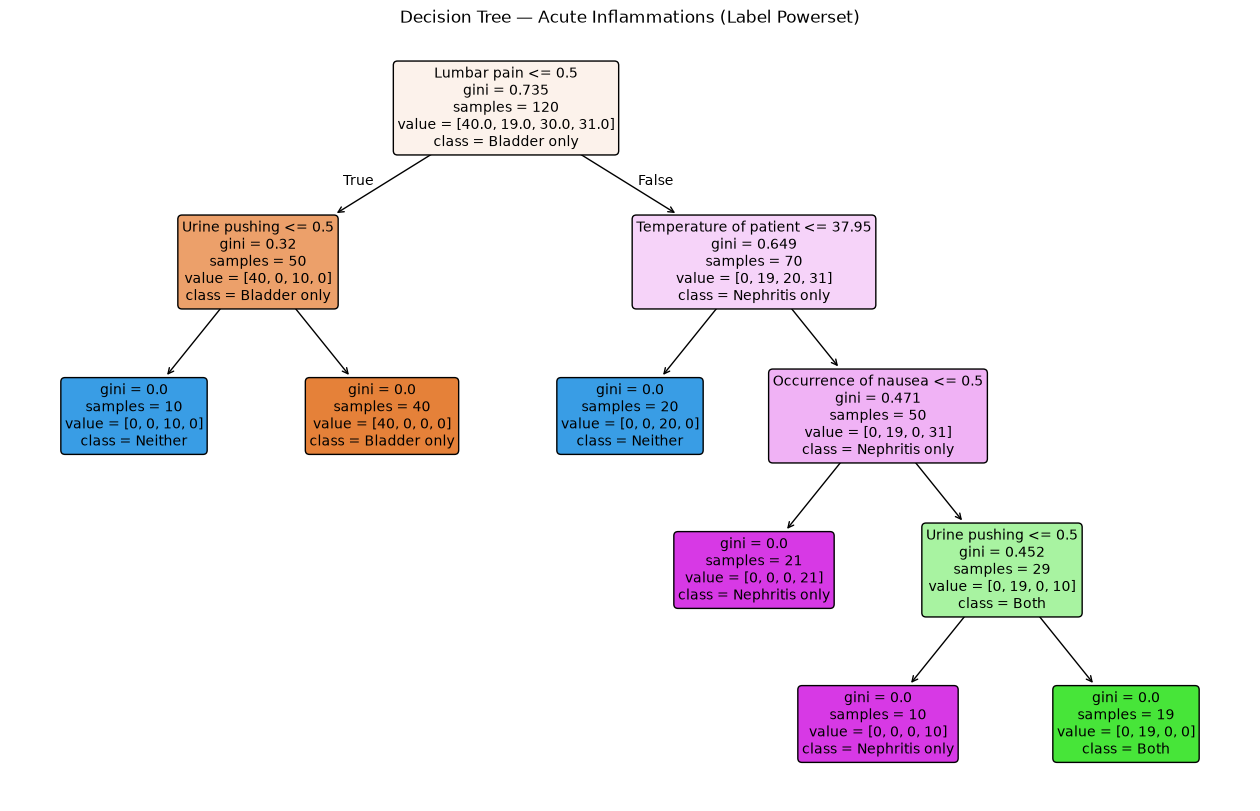

In [10]:
label_map = {(0, 0): 'Neither',
             (1, 0): 'Bladder only',
             (0, 1): 'Nephritis only',
             (1, 1): 'Both'}

y = Y.apply(lambda row: label_map[tuple(row)], axis=1)

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X, y)

plt.figure(figsize=(16, 10))
plot_tree(tree,
          feature_names=X.columns,
          class_names=tree.classes_,
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('Decision Tree — Acute Inflammations (Label Powerset)')
plt.show()





### (c) Convert the decision rules

In [11]:
def decision_rules(tree, feature_names):

    left      = tree.tree_.children_left
    right     = tree.tree_.children_right
    threshold = tree.tree_.threshold
    features  = [feature_names[i] for i in tree.tree_.feature]
    value     = tree.tree_.value

    def recurse(left, right, threshold, features, node, depth=0):
        indent = "    " * depth
        if (threshold[node] != -2):
            print(indent, "if ( " + features[node] + " <= " + str(threshold[node]) + " ) {")
            if left[node] != -1:
                recurse(left, right, threshold, features, left[node], depth + 1)
                print(indent, "} else {")
                if right[node] != -1:
                    recurse(left, right, threshold, features, right[node], depth + 1)
                print(indent, "}")
        else:
            print(indent, "return " + tree.classes_[value[node].argmax()])

    recurse(left, right, threshold, features, 0)

decision_rules(tree, list(X.columns))


 if ( Lumbar pain <= 0.5 ) {
     if ( Urine pushing <= 0.5 ) {
         return Neither
     } else {
         return Bladder only
     }
 } else {
     if ( Temperature of patient <= 37.95000076293945 ) {
         return Neither
     } else {
         if ( Occurrence of nausea <= 0.5 ) {
             return Nephritis only
         } else {
             if ( Urine pushing <= 0.5 ) {
                 return Nephritis only
             } else {
                 return Both
             }
         }
     }
 }


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [16]:
data_dir = 'Homework 5 Data/'

columns2 = []
with open(data_dir + 'communities.names') as f:
    for line in f:
        if line.startswith('@attribute'):
            columns2.append(line.split()[1])

communities = pd.read_csv(data_dir + 'communities.csv',
                          header=None,
                          names=columns2,
                          na_values='?')

communities.head()

train = communities.iloc[:1495]
test  = communities.iloc[1495:]




### (b) Missing values

In [17]:
target = 'ViolentCrimesPerPop'
non_predictive = ['state', 'county', 'community', 'communityname', 'fold']

train = train.drop(columns=non_predictive)
test  = test.drop(columns=non_predictive)

train_means = train.mean(numeric_only=True)
train = train.fillna(train_means)
test  = test.fillna(train_means)

X_train, y_train = train.drop(columns=target), train[target]
X_test,  y_test  = test.drop(columns=target),  test[target]

### (c) Plot a correlation matrix

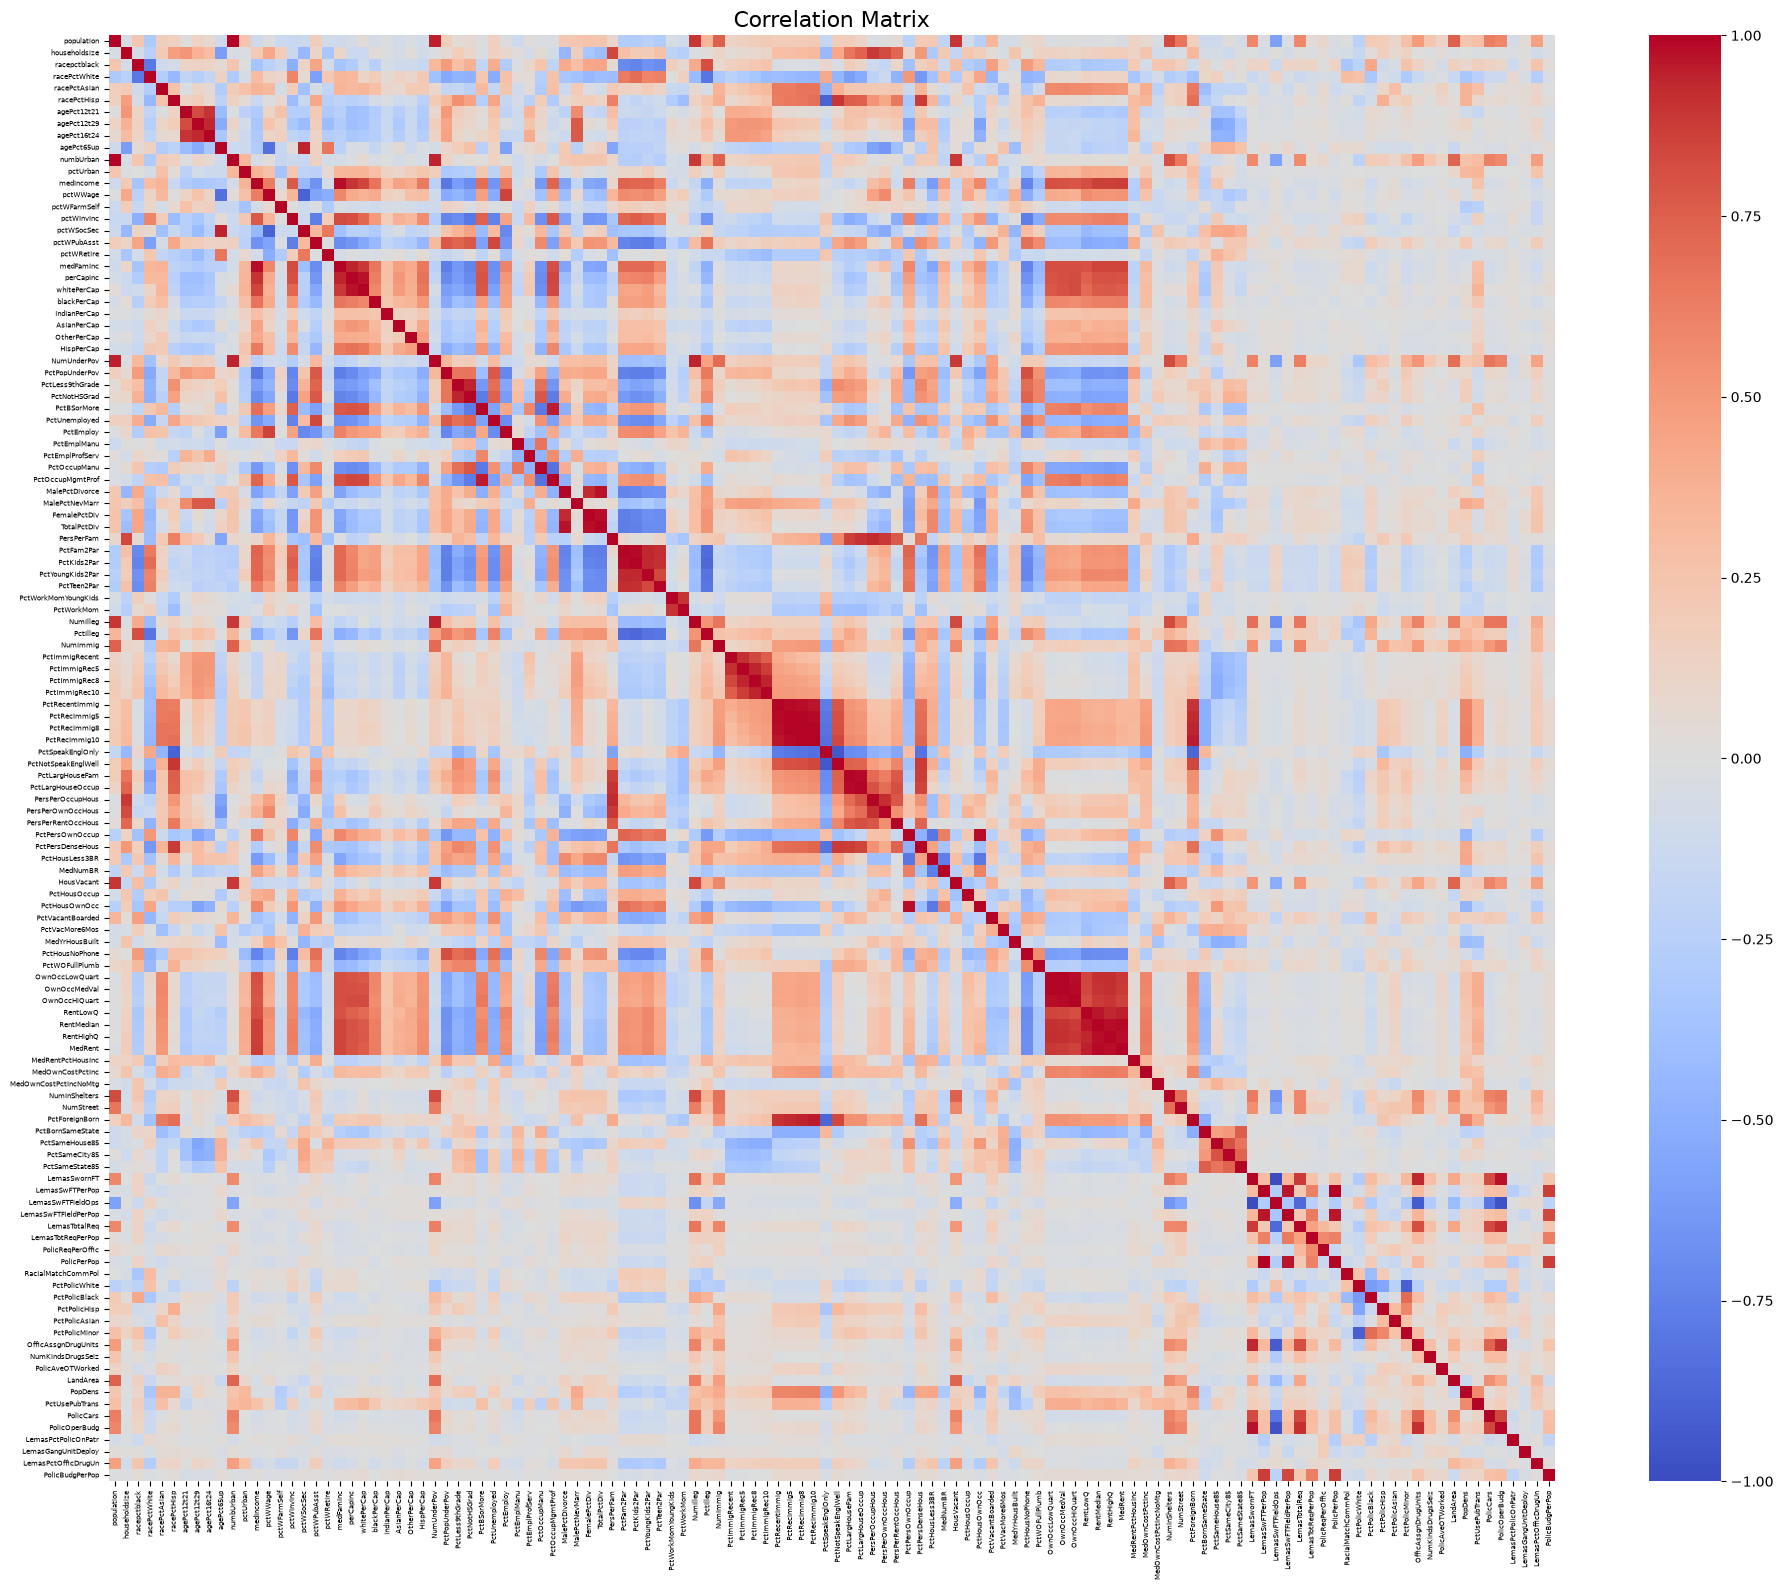

In [18]:
corr = X_train.corr()

plt.figure(figsize=(20, 16))
sns.heatmap(corr,
            cmap='coolwarm',       
            vmin=-1, vmax=1,       
            center=0,              
            square=True,
            xticklabels=True, yticklabels=True)
plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
plt.title('Correlation Matrix', fontsize=16)
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [20]:
cv = X_train.std() / X_train.mean()
cv = cv.sort_values(ascending=False)


### (e) Scatter plots and box plots for highest CV features

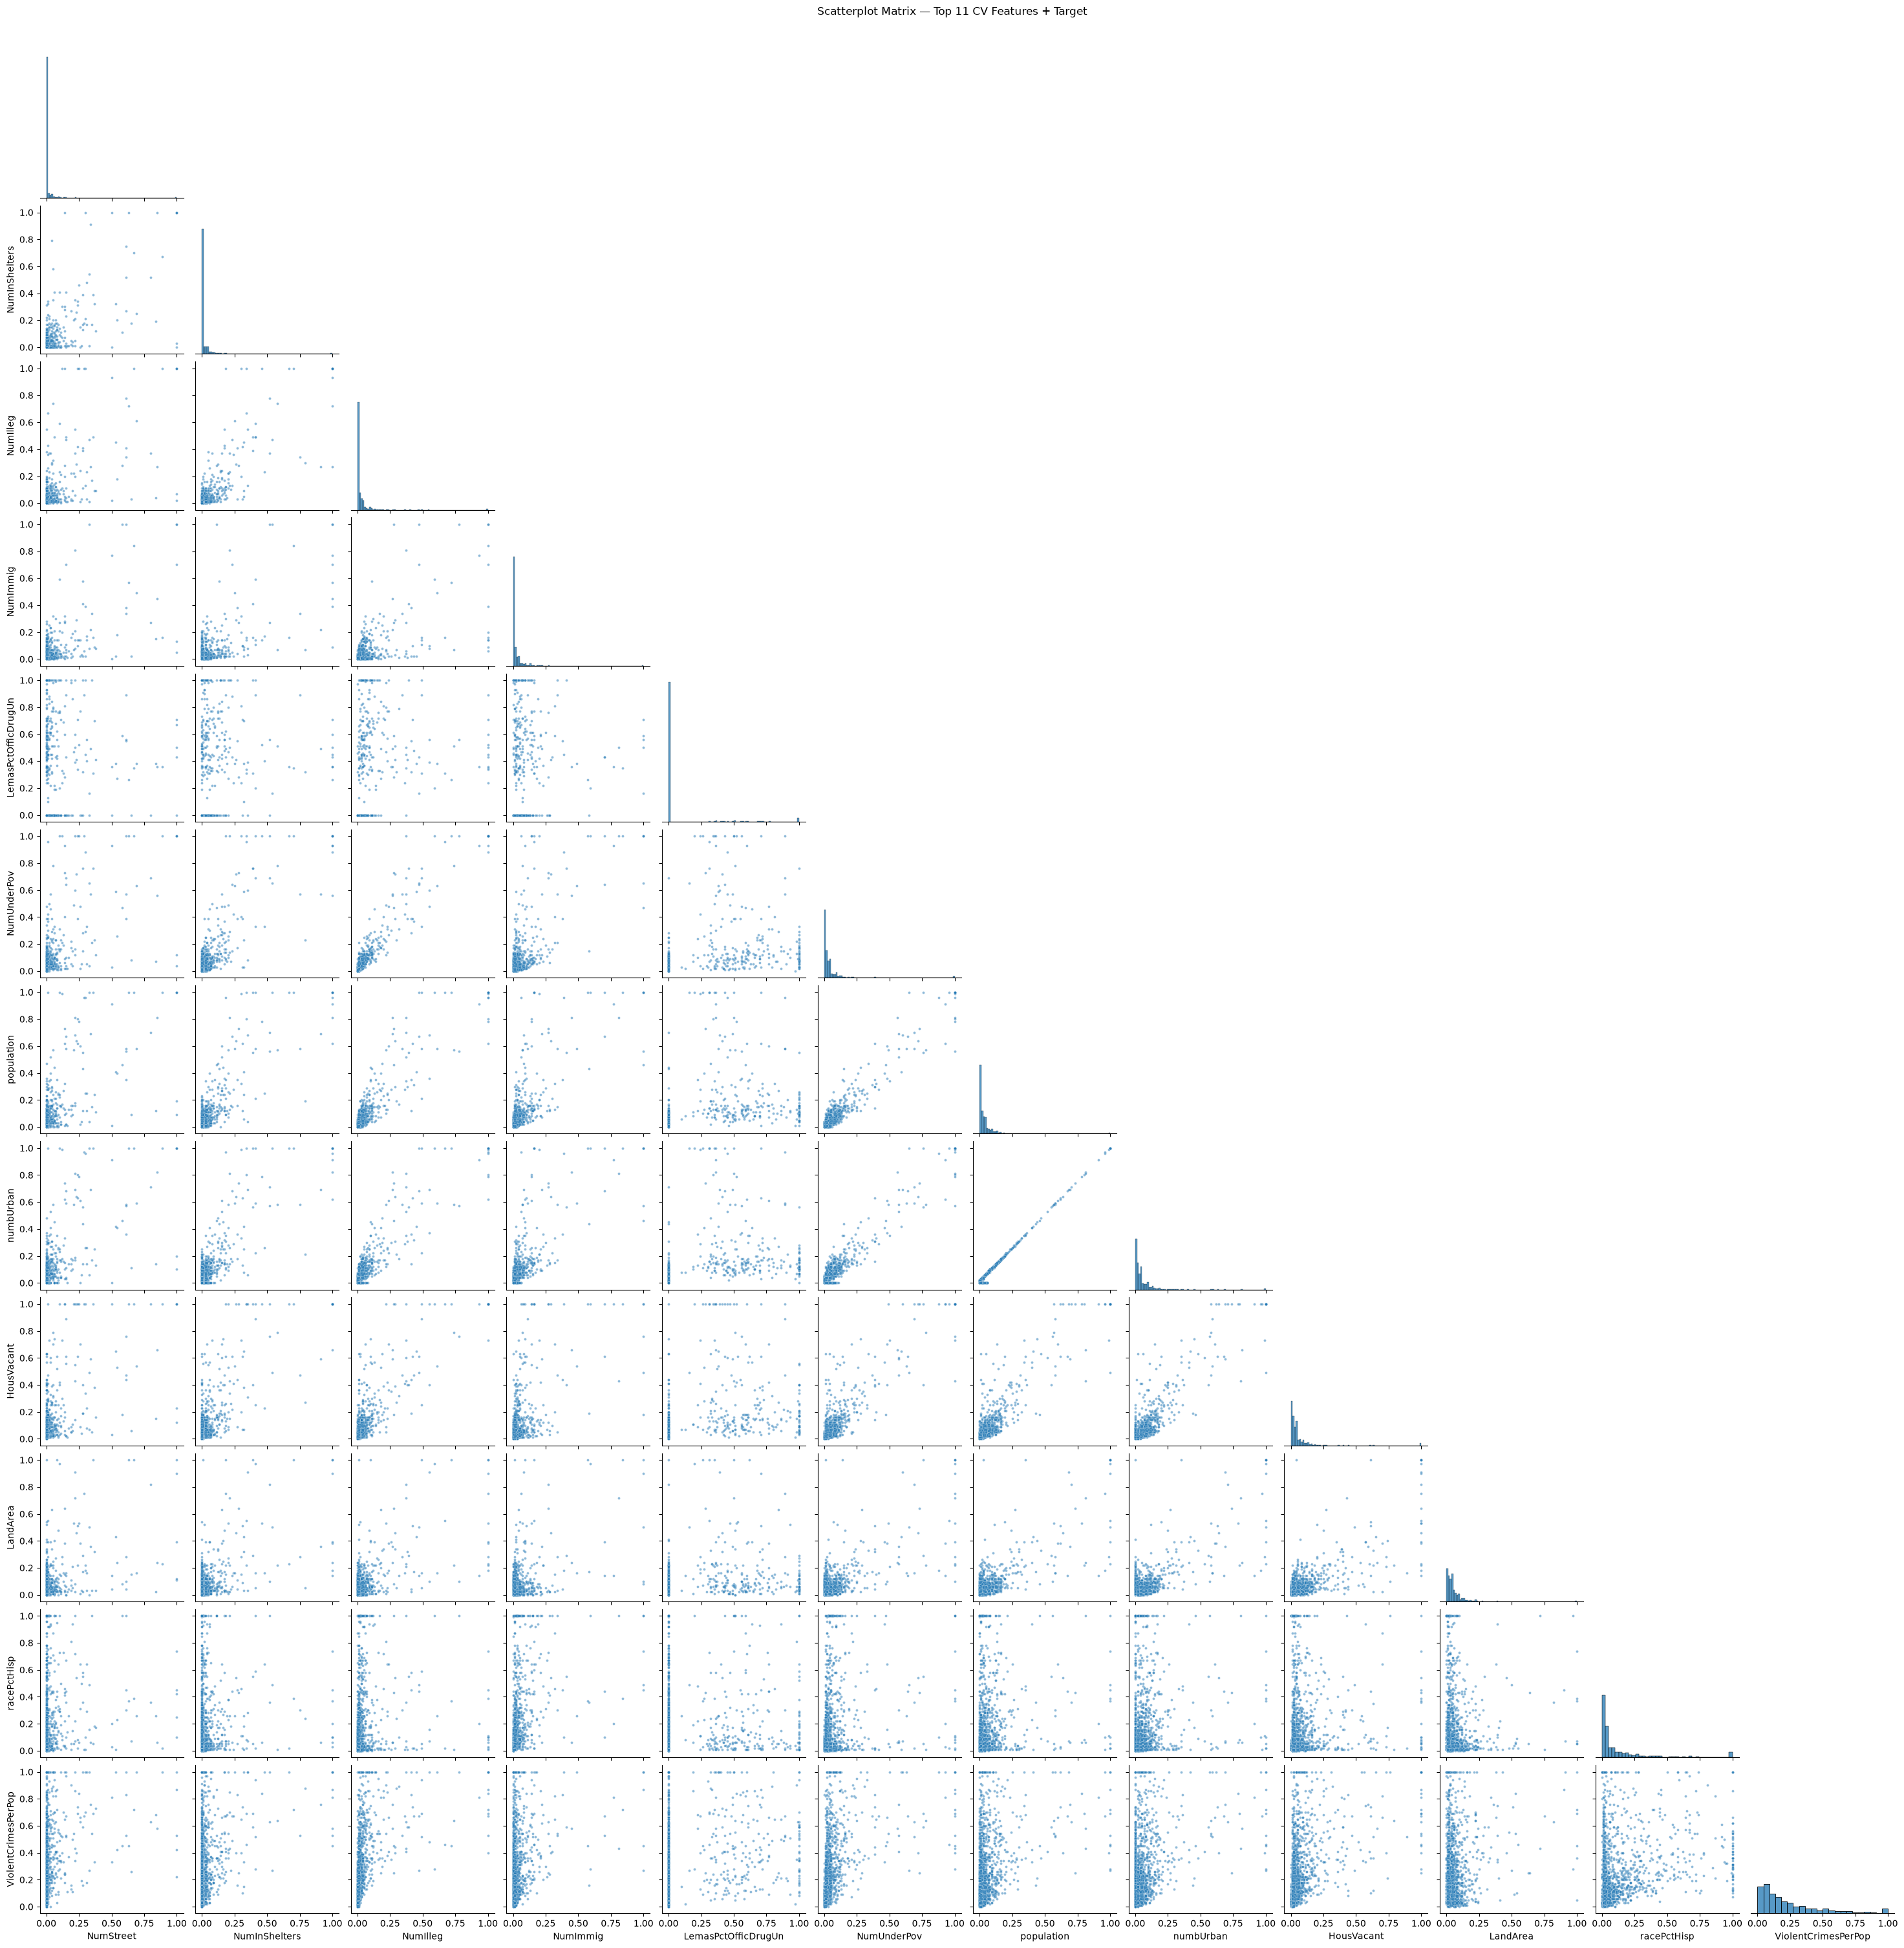

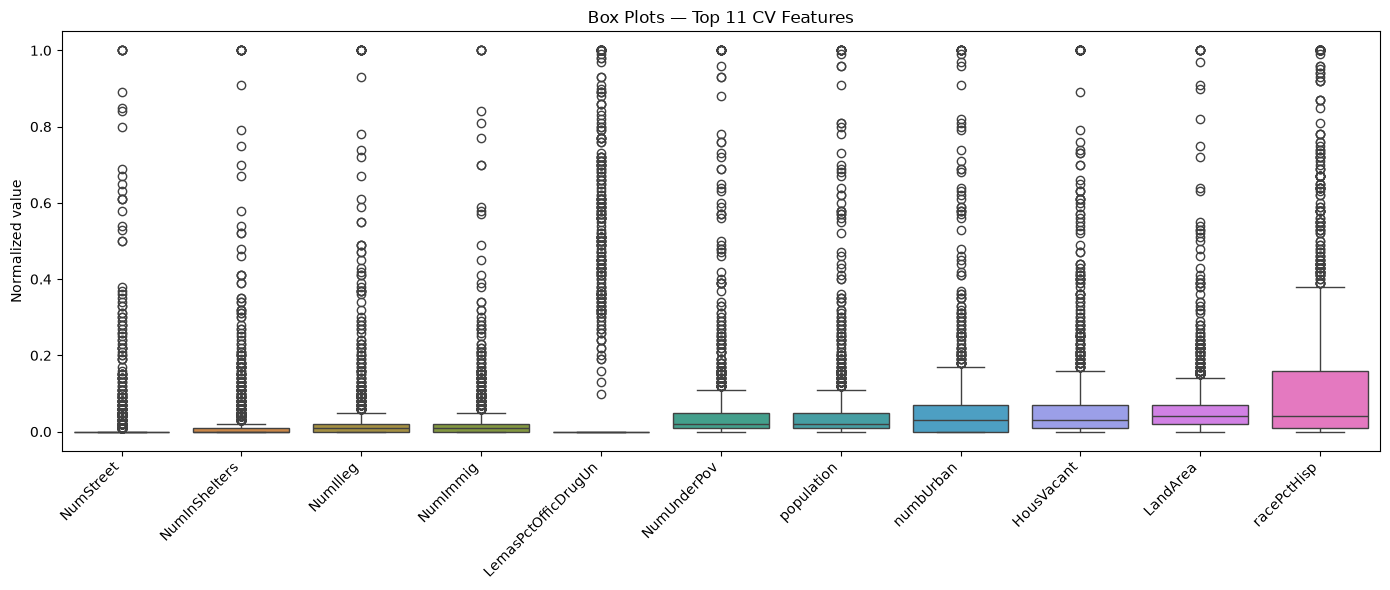

In [21]:
k = int(np.floor(np.sqrt(128)))
top_features = cv.head(k).index.tolist()

plot_df = X_train[top_features].copy()
plot_df[target] = y_train 

#scatter plot
sns.pairplot(plot_df, plot_kws={'s': 8, 'alpha': 0.5}, corner=True)
plt.suptitle('Scatterplot Matrix — Top 11 CV Features + Target', y=1.01)
plt.show()

#box plot
plt.figure(figsize=(14, 6))
sns.boxplot(data=X_train[top_features])
plt.xticks(rotation=45, ha='right')
plt.title('Box Plots — Top 11 CV Features')
plt.ylabel('Normalized value')
plt.tight_layout()
plt.show()

Most communities feature values cluster around 0 in scatterplot, which means they are small and don't tell us much about their significance. 

### (f) Fit a linear model

In [23]:
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
mse_lr = mean_squared_error(y_test, y_pred_lr)

print(f'Linear model test MSE: {mse_lr:.4f}')

Linear model test MSE: 0.0181


### (g) Fit a ridge regression model

In [24]:
alphas = np.logspace(-4, 4, 100)

ridge = RidgeCV(alphas=alphas, cv=10)
ridge.fit(X_train, y_train)

y_pred_ridge = ridge.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)

print(f'Best λ (alpha): {ridge.alpha_:.4f}')
print(f'Ridge test MSE: {mse_ridge:.4f}')

Best λ (alpha): 2.3101
Ridge test MSE: 0.0176


### (h) Fit a LASSO model

In [26]:
lasso = LassoCV(cv=10, max_iter=50000)
lasso.fit(X_train, y_train)

y_pred_lasso = lasso.predict(X_test)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)



coefs = pd.Series(lasso.coef_, index=X_train.columns)
selected = coefs[coefs != 0].sort_values(key=abs, ascending=False)

print("LASSO:")
print(f'Best λ (alpha): {lasso.alpha_:.6f}')
print(f'LASSO test MSE: {mse_lasso:.4f}')
print(f'{len(selected)} features selected')

#standardized LASSO
lasso_std = make_pipeline(StandardScaler(), LassoCV(cv=10, max_iter=50000))
lasso_std.fit(X_train, y_train)

y_pred_lasso_std = lasso_std.predict(X_test)
mse_lasso_std = mean_squared_error(y_test, y_pred_lasso_std)

lasso_model = lasso_std[-1]   # the LassoCV step inside the pipeline
coefs_std = pd.Series(lasso_model.coef_, index=X_train.columns)

print('Standardized features LASSO:')
print(f'Best λ (alpha): {lasso_model.alpha_:.6f}')
print(f'Standardized LASSO test MSE: {mse_lasso_std:.4f}')
print(f'{(coefs_std != 0).sum()} features selected')


LASSO:
Best λ (alpha): 0.000108
LASSO test MSE: 0.0178
77 features selected
Standardized features LASSO:
Best λ (alpha): 0.000664
Standardized LASSO test MSE: 0.0178
76 features selected


### (i) Fit a PCR model

In [28]:
pcr = Pipeline([
    ('scaler', StandardScaler()),
    ('pca',    PCA()),
    ('lr',     LinearRegression())
])

param_grid = {'pca__n_components': range(1, X_train.shape[1] + 1)}   

pcr_cv = GridSearchCV(pcr, param_grid,
                      cv=KFold(n_splits=10, shuffle=True, random_state=42),
                      scoring='neg_mean_squared_error')
pcr_cv.fit(X_train, y_train)

best_M = pcr_cv.best_params_['pca__n_components']
y_pred_pcr = pcr_cv.predict(X_test)
mse_pcr = mean_squared_error(y_test, y_pred_pcr)

print(f'Best M: {best_M}')
print(f'PCR test MSE: {mse_pcr:.4f}')

Best M: 96
PCR test MSE: 0.0184


### (j) Fit a boosting tree

In [29]:
xgb_model = xgb.XGBRegressor(
    n_estimators=300,      
    learning_rate=0.05,    
    max_depth=3,           
    random_state=42,
    n_jobs=-1              
)

param_grid = {'reg_alpha': np.logspace(-4, 1, 12)}   

xgb_cv = GridSearchCV(xgb_model, param_grid,
                      cv=KFold(n_splits=10, shuffle=True, random_state=42),
                      scoring='neg_mean_squared_error')
xgb_cv.fit(X_train, y_train)

best_alpha = xgb_cv.best_params_['reg_alpha']
y_pred_xgb = xgb_cv.predict(X_test)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)

print(f'Best alpha: {best_alpha:.4f}')
print(f'XGBoost test MSE: {mse_xgb:.4f}')

Best alpha: 1.2328
XGBoost test MSE: 0.0164
